In [2]:
from pathlib import Path
import sys
from collections import Counter
import matplotlib.pyplot as plt

root = Path.cwd().parent
sys.path.insert(0, str(root / "src"))

from preprocessing import Preprocessor

preprocessor = Preprocessor(
        image_size=(224, 224),
        path= str(root / "Data" ),
        classetr=[
            "glioma",
            "meningioma",
            "pituitary",
            "notumor"
        ]
    )

In [2]:
images, labels = preprocessor.load_images()

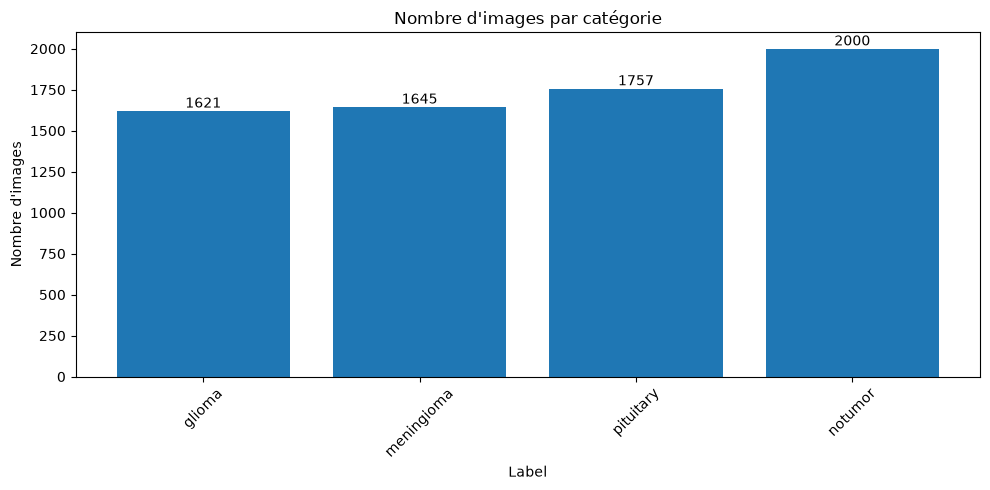

In [ ]:


label_counts = Counter(labels)


categories = list(label_counts.keys())
counts = list(label_counts.values())

plt.figure(figsize=(10, 5))
plt.bar(categories, counts)

plt.title("Nombre d'images par catégorie")
plt.xlabel("Label")
plt.ylabel("Nombre d'images")

for i, count in enumerate(counts):
    plt.text(i, count, str(count), ha="center", va="bottom")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

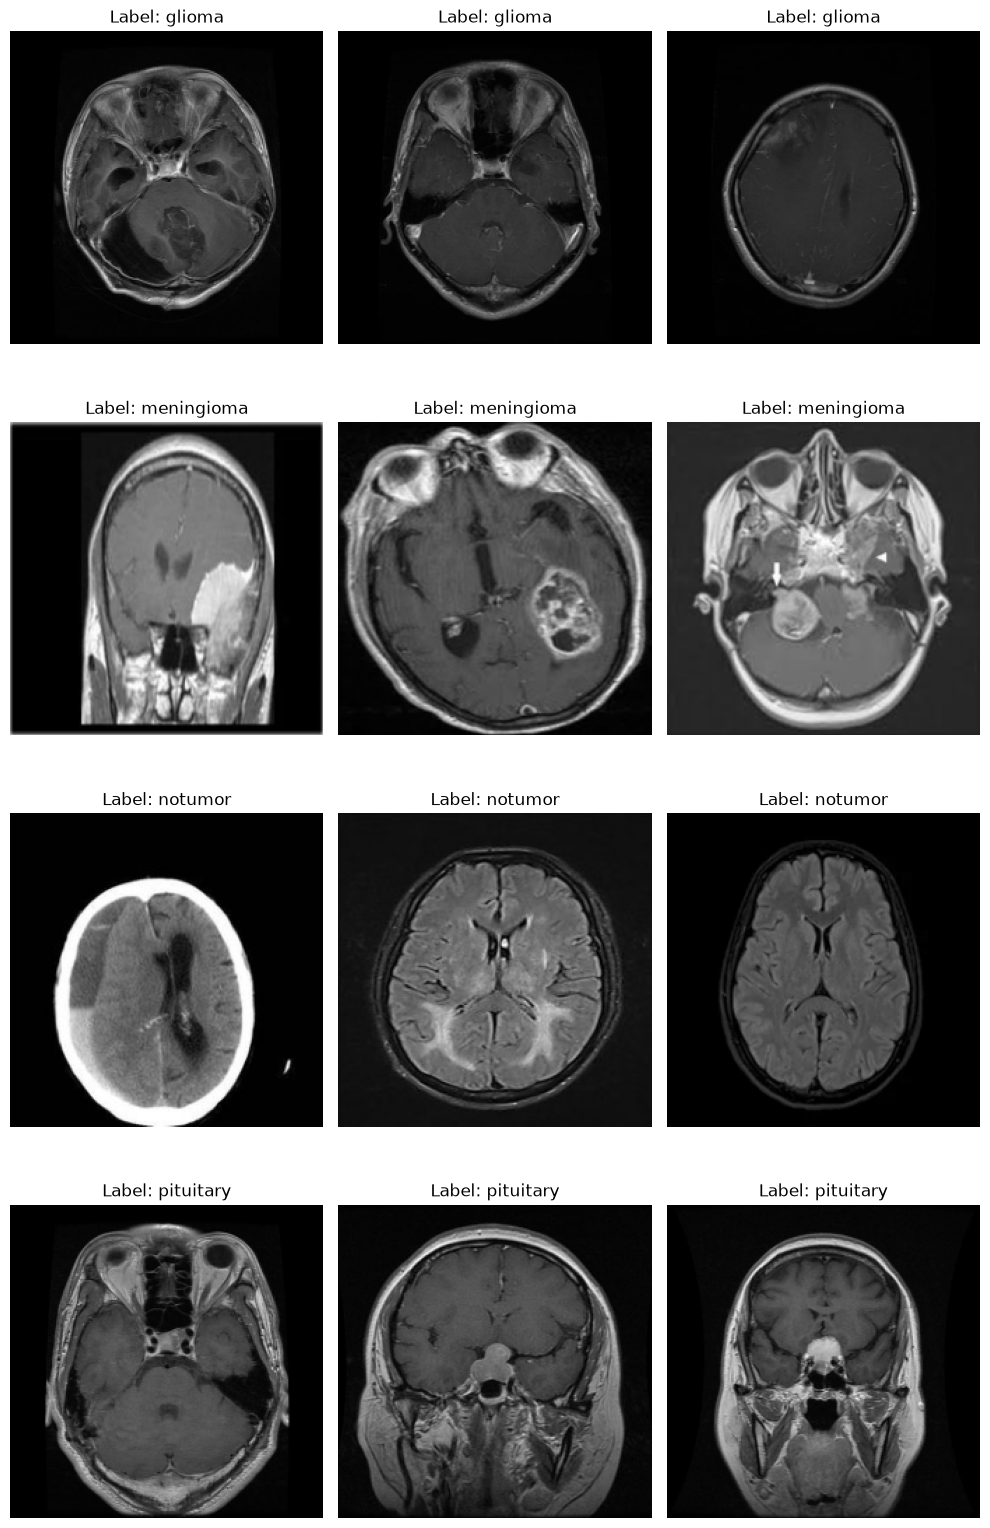

In [4]:
import numpy as np


categories = np.unique(labels)

fig, axes = plt.subplots(
    len(categories), 3,
    figsize=(10, 4 * len(categories))
)

for i, category in enumerate(categories):
    # Récupérer les indices des images de cette catégorie
    indices = np.where(np.array(labels) == category)[0][:3]

    for j, idx in enumerate(indices):
        axes[i, j].imshow(images[idx], cmap="gray")
        axes[i, j].set_title(f"Label: {category}")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [5]:
from tensorflow import keras
from tensorflow.keras import layers



model = keras.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(set(labels)), activation='softmax')
])

c:\Users\safiy\Desktop\les brief\BrainScan-D-tection-du-Cancer-C-r-bral-par-CNN\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [6]:
preprocessor.encode_labels()
preprocessor.normalize_images()
preprocessor.split_data(test_size=0.2, random_state=42)
preprocessor.split_data_validation()
X_train, y_train = preprocessor.get_train_data()
X_test, y_test = preprocessor.get_test_data()
X_val, y_val = preprocessor.get_validation_data()
labels = preprocessor.labels






In [7]:
print(type(labels))
print(labels.shape)
print(np.unique(labels))

<class 'numpy.ndarray'>
(7023,)
[0 1 2 3]


In [ ]:
model.compile(optimizer='adam',
loss='sparse_categorical_crossentropy',
metrics=['accuracy'])

In [9]:
model.fit(X_train, y_train, epochs=10, batch_size=32  , validation_data=(X_val, y_val)) 


Epoch 1/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 117s 782ms/step - accuracy: 0.6573 - loss: 0.8610 - val_accuracy: 0.8185 - val_loss: 0.4537
Epoch 2/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 144s 811ms/step - accuracy: 0.8714 - loss: 0.3546 - val_accuracy: 0.8657 - val_loss: 0.3470
Epoch 3/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 122s 867ms/step - accuracy: 0.9268 - loss: 0.2039 - val_accuracy: 0.8995 - val_loss: 0.2780
Epoch 4/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 111s 791ms/step - accuracy: 0.9524 - loss: 0.1306 - val_accuracy: 0.9093 - val_loss: 0.2873
Epoch 5/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 112s 793ms/step - accuracy: 0.9806 - loss: 0.0598 - val_accuracy: 0.9466 - val_loss: 0.2097
Epoch 6/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 147s 800ms/step - accuracy: 0.9891 - loss: 0.0353 - val_accuracy: 0.9431 - val_loss: 0.2357
Epoch 7/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 104s 733ms/step - accuracy: 0.9971 - loss: 0.0096 - val_accuracy: 0.9431 - val_loss: 0.2292
Epoch 8/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 95s 671ms/step - accuracy: 0.9964 - 

In [1]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

NameError: name 'model' is not defined

In [ ]:
#save the model
model.save("best_model.keras")